
# 🌸 Project 22: My Little Journal
## Notebook 01 — Data Exploration & Analysis

**Objective:** Explore the GoEmotions dataset, understand its emotion labels, examine class distributions, and prepare for preprocessing and model training.

**Dataset:** GoEmotions (Google Research)


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Python environment is ready!")

Python environment is ready!


### 1. Load the dataset

In [2]:
from datasets import load_dataset

# load the simplified GooEmotions dataset
dataset = load_dataset("google-research-datasets/go_emotions", "simplified")

# Display dataset structure
print(dataset)

README.md:   0%|          | 0.00/9.40k [00:00<?, ?B/s]

c:\Projects\22_My_Little_Journal_app\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\shwey\.cache\huggingface\hub\datasets--google-research-datasets--go_emotions. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Projects\22_My_Little_Journal_app\.venv\Lib\site-packages\huggingface_hub\file_downl

simplified/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.77MB            

simplified/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

simplified/validation-00000-of-00001.par(…): reconstructing file:   0%|          |  0.00B /  350kB            

...

simplified/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/43410 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5426 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5427 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 43410
    })
    validation: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 5426
    })
    test: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 5427
    })
})


### 2. Dataset Overview

In [4]:

# Convert the training split into a Pandas DataFrame
df = dataset["train"].to_pandas()

# Display the first 5 rows
df.head()


,text,labels,id
0,My favourite food is anything I didn't have to...,[27],eebbqej
1,"Now if he does off himself, everyone will thin...",[27],ed00q6i
2,WHY THE FUCK IS BAYLESS ISOING,[2],eezlygj
3,To make her feel threatened,[14],ed7ypvh
4,Dirty Southern Wankers,[3],ed0bdzj


### . Save the dataset locally

In [5]:

from pathlib import Path

# Project data directory
data_dir = Path.cwd().parent / "data" / "raw"
data_dir.mkdir(parents=True, exist_ok=True)

# Save all three original dataset splits
for split in ["train", "validation", "test"]:
    split_df = dataset[split].to_pandas()
    split_df.to_csv(data_dir / f"{split}.csv", index=False)

print("Dataset saved successfully!")
print("Location:", data_dir.resolve())


Dataset saved successfully!
Location: C:\Projects\22_My_Little_Journal_app\data\raw


### 3. Dataset Structure

Examine the dataset dimensions, column names, and data types.

In [6]:

# Check the shape of each dataset split
for split in ["train", "validation", "test"]:
    print(f"{split}: {dataset[split].shape}")

# Examine training data structure
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)


train: (43410, 3)
validation: (5426, 3)
test: (5427, 3)

Column names:
['text', 'labels', 'id']

Data types:
text         str
labels    object
id           str
dtype: object


### 4. Emotion Label Mapping

Convert numerical emotion labels into readable emotion names.

In [7]:

# Get emotion names from the dataset
emotion_names = dataset["train"].features["labels"].feature.names

# Display all emotion labels
for i, emotion in enumerate(emotion_names):
    print(f"{i}: {emotion}")


0: admiration
1: amusement
2: anger
3: annoyance
4: approval
5: caring
6: confusion
7: curiosity
8: desire
9: disappointment
10: disapproval
11: disgust
12: embarrassment
13: excitement
14: fear
15: gratitude
16: grief
17: joy
18: love
19: nervousness
20: optimism
21: pride
22: realization
23: relief
24: remorse
25: sadness
26: surprise
27: neutral


In [8]:

# Convert numerical labels into emotion names
df["emotion_names"] = df["labels"].apply(
    lambda labels: [emotion_names[int(i)] for i in labels]
)

# Display examples
df[["text", "labels", "emotion_names"]].head(10)


,text,labels,emotion_names
0,My favourite food is anything I didn't have to...,[27],[neutral]
1,"Now if he does off himself, everyone will thin...",[27],[neutral]
2,WHY THE FUCK IS BAYLESS ISOING,[2],[anger]
3,To make her feel threatened,[14],[fear]
4,Dirty Southern Wankers,[3],[annoyance]
5,OmG pEyToN iSn'T gOoD eNoUgH tO hElP uS iN tHe...,[26],[surprise]
6,Yes I heard abt the f bombs! That has to be wh...,[15],[gratitude]
7,We need more boards and to create a bit more s...,"[8, 20]","[desire, optimism]"
8,Damn youtube and outrage drama is super lucrat...,[0],[admiration]
9,It might be linked to the trust factor of your...,[27],[neutral]



### 5. Emotion Distribution

Analyze the frequency of each emotion label to identify class imbalance in the training dataset.


In [9]:

# Count each emotion across all training examples
emotion_counts = (
    df["emotion_names"]
    .explode()
    .value_counts()
)

# Display emotion frequencies
emotion_counts


emotion_names
neutral           14219
admiration         4130
approval           2939
gratitude          2662
annoyance          2470
amusement          2328
curiosity          2191
love               2086
disapproval        2022
optimism           1581
anger              1567
joy                1452
confusion          1368
sadness            1326
disappointment     1269
realization        1110
caring             1087
surprise           1060
excitement          853
disgust             793
desire              641
fear                596
remorse             545
embarrassment       303
nervousness         164
relief              153
pride               111
grief                77
Name: count, dtype: int64

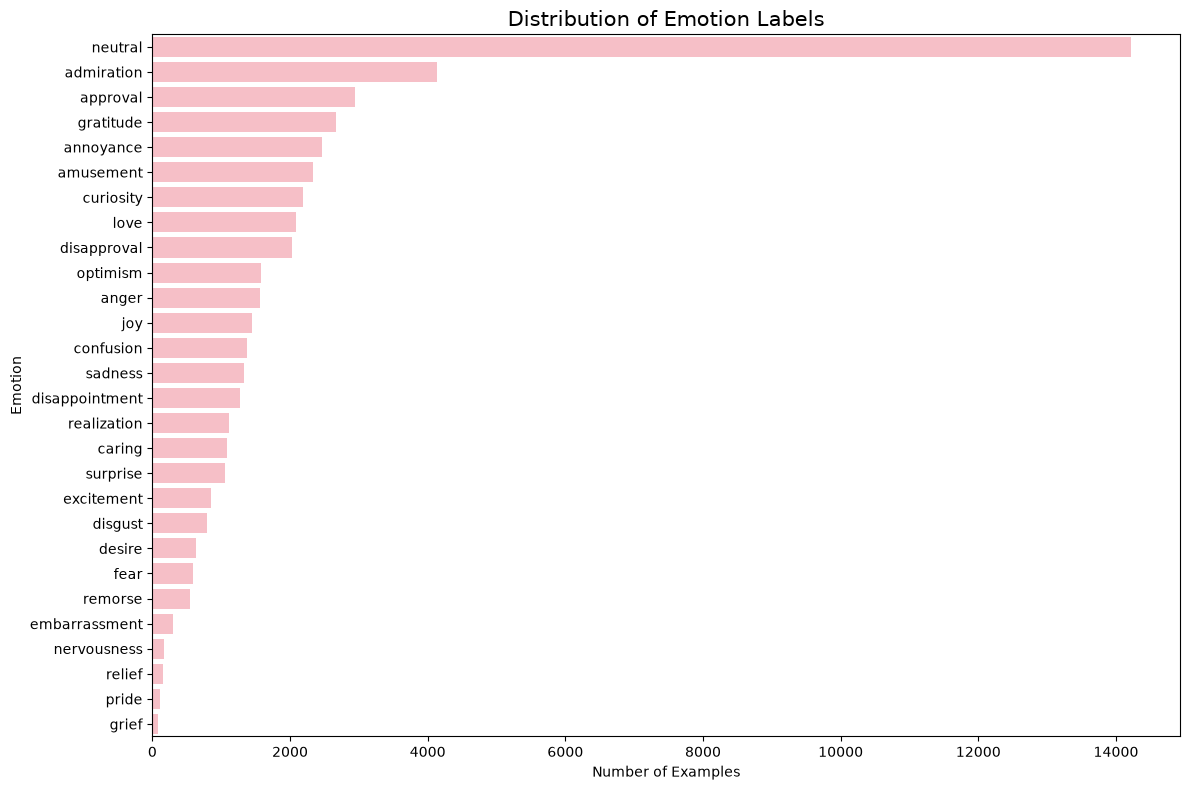

In [10]:

plt.figure(figsize=(12, 8))

sns.barplot(
    x=emotion_counts.values,
    y=emotion_counts.index,
    color="lightpink"
)

plt.title("Distribution of Emotion Labels", fontsize=15)
plt.xlabel("Number of Examples")
plt.ylabel("Emotion")
plt.tight_layout()
plt.show()



### 6. Data Quality Assessment

Check for missing values, duplicate entries, and empty text to identify potential data quality issues before preprocessing.


In [11]:

# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check duplicate text entries
print("\nDuplicate texts:", df["text"].duplicated().sum())

# Check empty or whitespace-only texts
print("Empty texts:", df["text"].str.strip().eq("").sum())

# Check total training examples
print("\nTotal examples:", len(df))


Missing values:
text             0
labels           0
id               0
emotion_names    0
dtype: int64

Duplicate texts: 183
Empty texts: 0

Total examples: 43410



### 7. Duplicate Text Investigation

Inspect duplicate comments and compare their emotion labels before deciding whether cleaning is necessary.


In [12]:

# Find all rows containing duplicated text
duplicates = df[
    df.duplicated(subset=["text"], keep=False)
].sort_values("text")

# Display duplicate comments and their labels
print("Rows involved in duplicates:", len(duplicates))

duplicates[["text", "emotion_names"]].head(20)


Rows involved in duplicates: 301


,text,emotion_names
1030,"A surprise to be sure, but a welcome one.",[optimism]
22935,"A surprise to be sure, but a welcome one.",[surprise]
41866,"A surprise to be sure, but a welcome one.",[excitement]
16095,Amen to that!,[approval]
37409,Amen to that!,[neutral]
891,Anytime :),[neutral]
26898,Anytime :),[neutral]
8434,Are you serious?,[curiosity]
27042,Are you serious?,"[confusion, curiosity]"
30285,Are you serious?,[curiosity]



### 8. Initial Data Quality Findings

- The training dataset contains 43,410 examples.
- No missing values or empty texts were found.
- 183 duplicate text occurrences were identified, involving 301 rows.
- Some identical texts have different emotion labels, suggesting contextual ambiguity or annotation differences.
- Duplicate records will be retained during EDA and reviewed before model training.



### 9. Text Length Analysis

Analyze the distribution of comment lengths to understand the characteristics of the text and guide preprocessing decisions.


In [13]:

# Calculate text length
df["char_count"] = df["text"].str.len()
df["word_count"] = df["text"].str.split().str.len()

# Display summary statistics
df[["char_count", "word_count"]].describe()


,char_count,word_count
count,43410.000000,43410.000000
mean,68.400875,12.840175
std,36.721898,6.701597
min,2.000000,1.000000
25%,38.000000,7.000000
50%,65.000000,12.000000
75%,96.000000,18.000000
max,703.000000,33.000000



### 10. Text Length Distribution

Visualize the distribution of word counts to understand typical comment lengths and identify unusually long entries.


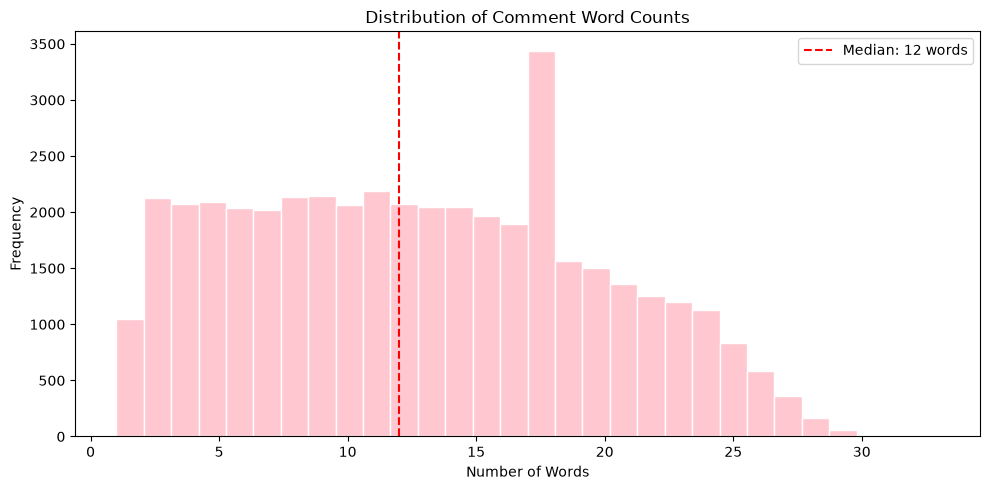

In [14]:

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="word_count",
    bins=30,
    color="lightpink",
    edgecolor="white"
)

plt.axvline(
    df["word_count"].median(),
    color="red",
    linestyle="--",
    label=f'Median: {df["word_count"].median():.0f} words'
)

plt.title("Distribution of Comment Word Counts")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()



**Observation:**
- Most comments are relatively short, with a median length of 12 words.
- The distribution shows mild right skewness and a noticeable peak around 17 words.
- Longer comments occur less frequently.
- Since journal entries may be substantially longer, text length must be considered during model development.



### 11. Emotion Co-occurrence Analysis

Analyze which emotion labels frequently appear together in the same text.


In [15]:

from itertools import combinations
from collections import Counter

# Count pairs of emotions appearing together
emotion_pairs = Counter()

for labels in df["emotion_names"]:
    unique_labels = sorted(set(labels))

    for pair in combinations(unique_labels, 2):
        emotion_pairs[pair] += 1

# Display the 15 most frequent emotion pairs
pairs_df = pd.DataFrame(
    [
        {"Emotion 1": a, "Emotion 2": b, "Count": count}
        for (a, b), count in emotion_pairs.most_common(15)
    ]
)

pairs_df


,Emotion 1,Emotion 2,Count
0,admiration,gratitude,279
1,anger,annoyance,269
2,admiration,approval,246
3,confusion,curiosity,212
4,approval,neutral,202
5,admiration,love,192
6,annoyance,disapproval,178
7,disappointment,sadness,133
8,annoyance,neutral,132
9,admiration,joy,126



**Observations:**
- Admiration and gratitude form the most frequent emotion pair (279 occurrences).
- Related emotions, such as anger and annoyance, frequently co-occur.
- Some pairs contain neutral and emotional labels, indicating annotation complexity.
- These findings support a multi-label classification approach.
- Raw co-occurrence frequencies do not necessarily indicate strong statistical associations.



### 12. Emotion Co-occurrence Heatmap

Visualize the frequency of emotion pairs using a heatmap to identify common multi-label combinations.


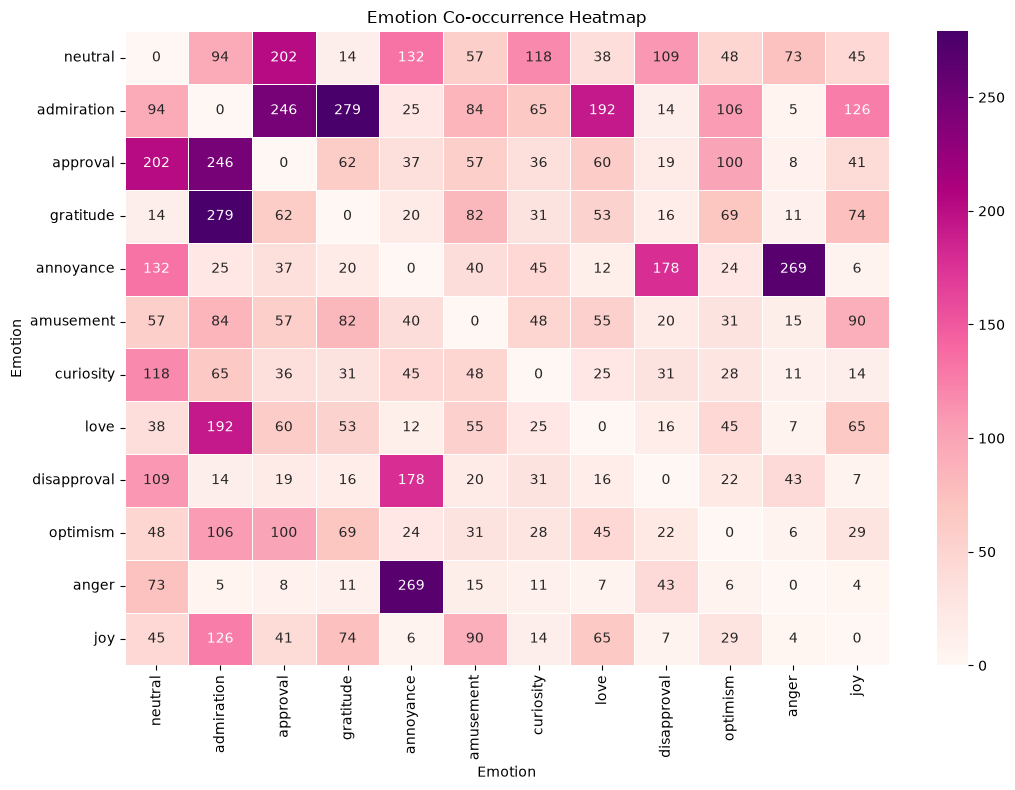

In [16]:

# Create a co-occurrence matrix
co_matrix = pd.DataFrame(
    0,
    index=emotion_names,
    columns=emotion_names
)

# Fill the matrix with emotion pair frequencies
for (emotion1, emotion2), count in emotion_pairs.items():
    co_matrix.loc[emotion1, emotion2] = count
    co_matrix.loc[emotion2, emotion1] = count

# Select the 12 most frequent emotions
top_emotions = emotion_counts.head(12).index

# Plot the heatmap
plt.figure(figsize=(11, 8))

sns.heatmap(
    co_matrix.loc[top_emotions, top_emotions],
    annot=True,
    fmt="d",
    cmap="RdPu",
    linewidths=0.5
)

plt.title("Emotion Co-occurrence Heatmap")
plt.xlabel("Emotion")
plt.ylabel("Emotion")
plt.tight_layout()
plt.show()



**Observations:**
- Admiration and gratitude have the highest co-occurrence count (279).
- Anger and annoyance are the second most frequent pair (269).
- Related emotions frequently appear together.
- The heatmap is symmetric because emotion pairs are unordered.
- Multi-label classification is suitable for capturing overlapping emotions.



### 13. Train–Validation–Test Overlap

Check for identical text entries across dataset splits to identify potential data leakage.


In [17]:

# Extract text from each dataset split
train_texts = set(dataset["train"]["text"])
val_texts = set(dataset["validation"]["text"])
test_texts = set(dataset["test"]["text"])

# Check overlapping texts
train_val_overlap = train_texts & val_texts
train_test_overlap = train_texts & test_texts
val_test_overlap = val_texts & test_texts

print("Train–Validation overlap:", len(train_val_overlap))
print("Train–Test overlap:", len(train_test_overlap))
print("Validation–Test overlap:", len(val_test_overlap))


Train–Validation overlap: 41
Train–Test overlap: 32
Validation–Test overlap: 10



### 14. Data Leakage Findings

**Observations:**
- Train–Validation overlap: 41 unique texts.
- Train–Test overlap: 32 unique texts.
- Validation–Test overlap: 10 unique texts.
- Exact text overlap may cause data leakage and overly optimistic evaluation results.

**Decision:**
- Preserve the original datasets.
- Remove overlapping texts from the training and validation sets while retaining the original test set.
- Perform cleaning before model training to improve evaluation reliability.


### Key Findings
- The training dataset contains 43,410 text examples and 28 emotion labels.
- The dataset supports multi-label emotion classification.
- No missing values or empty texts were found.
- Duplicate texts were identified, including examples with different emotion annotations.
- Comments are generally short, with a median length of 12 words.
- Related emotions frequently co-occur.
- Exact text overlap was detected across training, validation, and test splits.